In [1]:
import time

import bloqade.tsim
import numpy as np
import stim
import tsim
from bloqade import squin
from cultivation import batches, circuit_path, plot, points
from tqdm import tqdm

In [2]:
@squin.kernel
def main():
    q = squin.qalloc(3)
    squin.broadcast.reset(q)
    squin.h(q[0])
    squin.t(q[0])
    squin.h(q[0])
    squin.cx(q[0], q[2])
    for i in [0, 2]:
        squin.depolarize(0.5, q[i])
        squin.cx(q[i], q[1])
    squin.measure(q[1])
    squin.cx(q[1], q[0])
    squin.broadcast.measure([q[0], q[2]])

In [3]:
c = bloqade.tsim.Circuit(main)
c

tsim.Circuit('''
R 0 1 2
H 0
T 0
H 0
CX 0 2
DEPOLARIZE1(0.5) 0
CX 0 1
DEPOLARIZE1(0.5) 2
CX 2 1
M(0) 1
CX 1 0
M(0) 0 2
''')

In [4]:
c.diagram(height=150)

In [5]:
c.diagram("zx")

'<div id="zxp-c969faf624dd4aa682d8c155c858f28e" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [6]:
sampler = c.compile_sampler()

In [7]:
samples = sampler.sample(shots=1_000_000)
samples

array([[ True,  True,  True],
       [ True,  True,  True],
       [ True, False, False],
       ...,
       [False, False, False],
       [ True, False, False],
       [False,  True,  True]], shape=(1000000, 3))

  0%|          | 0/18 [00:00<?, ?it/s]

  6%|▌         | 1/18 [00:00<00:15,  1.07it/s]

 11%|█         | 2/18 [00:01<00:09,  1.68it/s]

 17%|█▋        | 3/18 [00:01<00:06,  2.49it/s]

 22%|██▏       | 4/18 [00:01<00:04,  3.31it/s]

 28%|██▊       | 5/18 [00:01<00:03,  4.10it/s]

... (10 outputs left out)

 89%|████████▉ | 16/18 [00:04<00:00,  5.61it/s]

 94%|█████████▍| 17/18 [00:04<00:00,  6.36it/s]

100%|██████████| 18/18 [00:04<00:00,  6.84it/s]

100%|██████████| 18/18 [00:04<00:00,  4.22it/s]

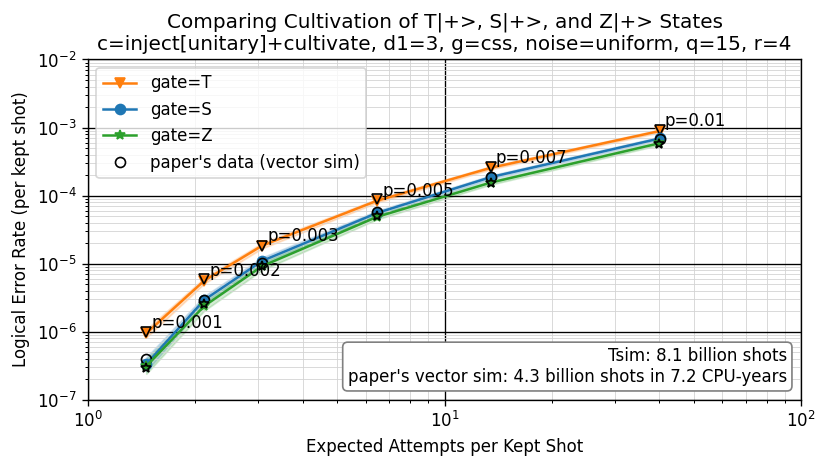

In [8]:
# Gidney, Shutty & Jones, "Magic state cultivation" (arXiv:2409.17595): cultivating T|+⟩ vs S|+⟩ vs Z|+⟩.
tally = points()  # gates T, S, Z at six noise strengths
b = 2**26
for point in tqdm(tally):
    circuit = tsim.Circuit.from_file(circuit_path(point))
    sampler = circuit.compile_detector_sampler()
    mask = np.ones(circuit.num_detectors, dtype=bool)  # postselect: keep shots where no detector fires
    for _ in batches(point):
        detectors, observables = sampler.sample(
            b, postselection_mask=mask, separate_observables=True, bit_packed=True
        )
        point.shots += b 
        point.kept += len(observables)
        point.errors += np.count_nonzero(observables)  # logical error: the observable flipped

plot(tally)

Circuits are represented as parameterized ZX diagrams, which are compiled into a contiguous datastructure for efficient sampling.

In [9]:
c.diagram("zx", scale=35);

Here, TSIM makes use of ZX diagrams in _doubled_ notation:


<img src="../figures/doubling.png" alt="doubled notation" width=650px>

In [10]:
tsim.Circuit("CNOT 0 1").diagram("zx")

'<div id="zxp-fb198b763e444b1cb0cc5a4382737fc1" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [11]:
tsim.Circuit("M 0").diagram("zx")

'<div id="zxp-eedb9abc481e424ca67f748e70c48ddf" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [12]:
tsim.Circuit("""
    X 0
    R 0
""").diagram("zx")

'<div id="zxp-2f3943fcc80b4bcbaaa8697cfcf6d82f" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [13]:
tsim.Circuit("""
M !0
CNOT rec[-1] 1
""").diagram("zx")

'<div id="zxp-cfe3ec19a8374d50b00cd1c3b77ea9b5" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

Pauli Channels are represented as parameterized Pauli vertices:

In [14]:
tsim.Circuit("""
    Z_ERROR(0.01) 0
""").diagram("zx")

'<div id="zxp-fd9f666d83c748ef83cbe95ed1fb24b6" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [15]:
tsim.Circuit("""DEPOLARIZE2(0.01) 0 1""").diagram("zx")

'<div id="zxp-adcff4f93e2c477abf6f01b0e751e72b" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

For QEC experiments, we are often not interested in measurements themselves, but certain XOR combinations of them, referred to as _detectors_. We can directly represent detectors in ZX diagrams by applying classical XORs to measurement bits. The XOR has a simple ZX representation:

<img src="../figures/xor.png" alt="XOR gate" width=350px>

In [16]:
c = tsim.Circuit("""
    R 0 1
    H 0
    CNOT 0 1
    M 0 1
    DETECTOR rec[-1] rec[-2]
    OBSERVABLE_INCLUDE(0) rec[-1]
""")
c.diagram("zx")

'<div id="zxp-e9052fb3e7254e1dabf9d3ae81801761" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [17]:
sampler = c.compile_sampler()
sampler.sample(10)

array([[False, False],
       [False, False],
       [ True,  True],
       [False, False],
       [ True,  True],
       [ True,  True],
       [False, False],
       [ True,  True],
       [ True,  True],
       [False, False]])

In [18]:
detector_sampler = c.compile_detector_sampler()
detectors = detector_sampler.sample(10)

In [19]:
mask = detectors == 0

# Clifford sampling

In [20]:
p = 1e-4
stim_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=7,
    distance=7,
    before_round_data_depolarization=p,
    before_measure_flip_probability=p,
    after_clifford_depolarization=p,
    after_reset_flip_probability=p,
)
stim_sampler = stim_circuit.compile_detector_sampler()

circuit = tsim.Circuit.from_stim_program(stim_circuit)
sampler = circuit.compile_detector_sampler()

In [21]:
circuit.without_noise().diagram("timeslice-svg", height=250, rows=1)

In [22]:
circuit.diagram("zx-dets")

'<div id="zxp-39b91431640f4ceca20672067a6ff9e0" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [23]:
num_samples = 1024**2*16

start = time.perf_counter()
samples = sampler.sample(shots=num_samples, bit_packed=True)
end = time.perf_counter()
print(f"Shots per second (Tsim): {num_samples / (end - start) / 1e6:.1f}M")

Shots per second (Tsim): 278.9M


## Non-Clifford circuits

In [24]:
c = tsim.Circuit.from_file("../circuits/msd_3.stim")
c.diagram(height=500)

In [25]:
c.diagram("zx-dets", scale_horizontally=1.3)

'<div id="zxp-f51014f4c70c481c9b5adcfb9b36049a" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [26]:
from compilation_widget import pauli_program

pauli_program()

# Fault distance of non-Clifford circuits (experimental)

`tsim.experimental.shortest_errors(circuit, max_weight=k)` returns every smallest set of faults that flips an observable without flipping a detector, like Stim's `search_for_undetectable_logical_errors`, but for circuits with T gates. The search is exhaustive and exact: with T gates, a set of faults goes undetected and flips the logical only with some probability, which Tsim computes from the statevector. An empty result proves that the distance is above `k`.

The d=5 magic state cultivation circuit of [Gidney, Shutty and Jones](https://arxiv.org/abs/2409.17595) is designed for fault distance 4, a property checked on its Clifford (S-state) proxy. [Chan et al.](https://arxiv.org/abs/2609.17706) showed that the actual T-state circuit only has distance 3:

In [27]:
from cultivation.chan import load_t_circuit, show_errors
from tsim.experimental import shortest_errors

circuit = load_t_circuit("d5a19_inject+cultivate_p1e-3.stim")  # Gidney et al.'s d=5 circuit, S → T
errors = shortest_errors(circuit, max_weight=4)

print(f"fault distance {len(errors[0])}: {len(errors)} logical errors\n")
show_errors(errors)  # the detectors that each fault flips

fault distance 3: 9 logical errors

D105  +  D105 D106  +  D106
    P(undetected) = 0.062, P(logical flip) = 0.031
D98  +  D98 D99  +  D99
    P(undetected) = 0.062, P(logical flip) = 0.031
D105  +  D105 D106  +  D106
    P(undetected) = 0.062, P(logical flip) = 0.031


Chan et al. restore the distance by adding 13 Z-flag qubits to the final double check:

In [28]:
circuit = load_t_circuit("d5a19f13_inject+cultivate_p1e-3.stim")  # with Chan et al.'s Z flags
errors = shortest_errors(circuit, max_weight=4)

print(f"fault distance {len(errors[0])}: {len(errors)} logical errors\n")
show_errors(errors)

fault distance 4: 84 logical errors

D50 D71  +  D50 D69 D70 D71  +  D69 D70 D104  +  D104 L0
    P(undetected) = 1.000, P(logical flip) = 1.000
D50 D71  +  D50 D70 D71  +  D70 D104  +  D104 L0
    P(undetected) = 1.000, P(logical flip) = 1.000
D50 D71  +  D50 D68  +  D68 D71 D104 D110  +  D104 D110 L0
    P(undetected) = 1.000, P(logical flip) = 1.000


# Determined measurements (experimental)

A measurement parity is *determined* if every noiseless shot gives it the same value; only such parities can be detectors. Stim's `count_determined_measurements` and `missing_detectors` find them for Clifford circuits. `tsim.experimental` has non-Clifford versions, plus `nondeterministic_detectors`, which lists the declared detectors and observables that are random without noise.

They catch a bug that the Clifford proxy hides. Gidney et al.'s d=5 circuit needs feedforward before its S gates can become T gates. Without it, the T-state circuit has 2 fewer determined parities than its S proxy, and 4 of its detectors are random. `missing_detectors` returns the determined parities that are not yet detectors, listing parities of the random detectors first: these heal the circuit.

In [29]:
from cultivation.chan import load_s_proxy
from tsim.experimental import count_determined_measurements, missing_detectors, nondeterministic_detectors

s_proxy = load_s_proxy("d5a19_inject+cultivate_uncorrected.stim")  # noiseless, without the feedforward
circuit = load_t_circuit("d5a19_inject+cultivate_uncorrected.stim")

print("measurements:", circuit.num_measurements)
print("determined parities, S proxy (Stim):", s_proxy.count_determined_measurements())
print("determined parities, T circuit (Tsim):", count_determined_measurements(circuit))

measurements: 112
determined parities, S proxy (Stim): 108
determined parities, T circuit (Tsim): 106


In [30]:
print("random detectors:", nondeterministic_detectors(circuit))
missing_detectors(circuit)

random detectors: [stim.DemTarget('D69'), stim.DemTarget('D91'), stim.DemTarget('D97'), stim.DemTarget('D102')]


stim.Circuit('''
    DETECTOR rec[-46] rec[-45] rec[-16] rec[-10]
    DETECTOR rec[-47] rec[-45] rec[-39] rec[-16] rec[-5]
''')